# Laboratorio OpenDSS & py-dss-interface
## Módulo 5: Control Inteligente de Inversores Avanzados (Volt-Var y Volt-Watt - IEEE 1547-2018)

---

### Objetivos de Aprendizaje
Al finalizar este cuaderno, el estudiante será capaz de:
1. Comprender las funciones de soporte a la red de los inversores inteligentes (*Smart Inverters*) según el estándar **IEEE 1547-2018** y **UL 1741-SB**.
2. Formular e implementar la curva de control autónomo **Volt-Var** ($Q(V)$) para absorber potencia reactiva inductiva durante sobretensiones.
3. Formular e implementar la curva de protección **Volt-Watt** ($P(V)$) para realizar corte (*curtailment*) controlado de potencia activa ante sobretensiones severas.
4. Programar un algoritmo de control en bucle cerrado mediante `py-dss-interface` para simular la convergencia de inversores autónomos.
5. Comparar el desempeño técnico-económico: Factor de potencia unitario vs Volt-Var puro vs Volt-Var + Volt-Watt combinado.

---
### 1. Marco Teórico: Control Autónomo según IEEE 1547-2018

Cuando un inversor inyecta potencia activa en un alimentador de distribución, la variación de tensión nodal es:

$$\Delta V pprox rac{P_{	ext{iny}} \cdot R - Q_{	ext{absorb}} \cdot X}{V_{	ext{nom}}}$$

Para mitigar la sobretensión producida por $P_{	ext{iny}} \cdot R > 0$, el inversor puede absorber potencia reactiva ($Q_{	ext{absorb}} > 0$, comportamiento inductivo), introduciendo una caída contraria $-Q_{	ext{absorb}} \cdot X$.

#### Función 1: Control Volt-Var ($Q(V)$)
El inversor mide la tensión eficaz en su terminal $V_{	ext{pu}}$ y modula su reactivo siguiendo una función por tramos:

$$Q(V) = egin{cases} 
+Q_{	ext{máx}} & V \le V_1 \quad (0.92	ext{ pu, inyección capacitiva}) \
	ext{Rampa capacitiva} & V_1 < V < V_2 \quad (0.92 \sim 0.98	ext{ pu}) \
0 & V_2 \le V \le V_3 \quad (0.98 \sim 1.02	ext{ pu, Banda Muerta}) \
	ext{Rampa inductiva} & V_3 < V < V_4 \quad (1.02 \sim 1.06	ext{ pu}) \
-Q_{	ext{máx}} & V \ge V_4 \quad (1.06	ext{ pu, absorción inductiva máxima})
\end{cases}$$

Donde típicamente $Q_{	ext{máx}} = \sqrt{S_{	ext{rated}}^2 - P^2} pprox 0.44 \cdot S_{	ext{rated}}$.

#### Función 2: Control Volt-Watt ($P(V)$)
Si la absorción reactiva llega a su límite y la tensión sigue aproximándose al límite crítico (ej. $1.06	ext{ pu}$), el inversor reduce progresivamente su potencia activa (*curtailment*):

$$P(V) = egin{cases} 
P_{	ext{mpp}} & V \le V_{	ext{start}} \quad (1.05	ext{ pu}) \
P_{	ext{mpp}} \cdot \left[1 - rac{V - V_{	ext{start}}}{V_{	ext{stop}} - V_{	ext{start}}}ight] & V_{	ext{start}} < V \le V_{	ext{stop}} \quad (1.05 \sim 1.08	ext{ pu}) \
0 & V > V_{	ext{stop}} \quad (1.08	ext{ pu})
\end{cases}$$


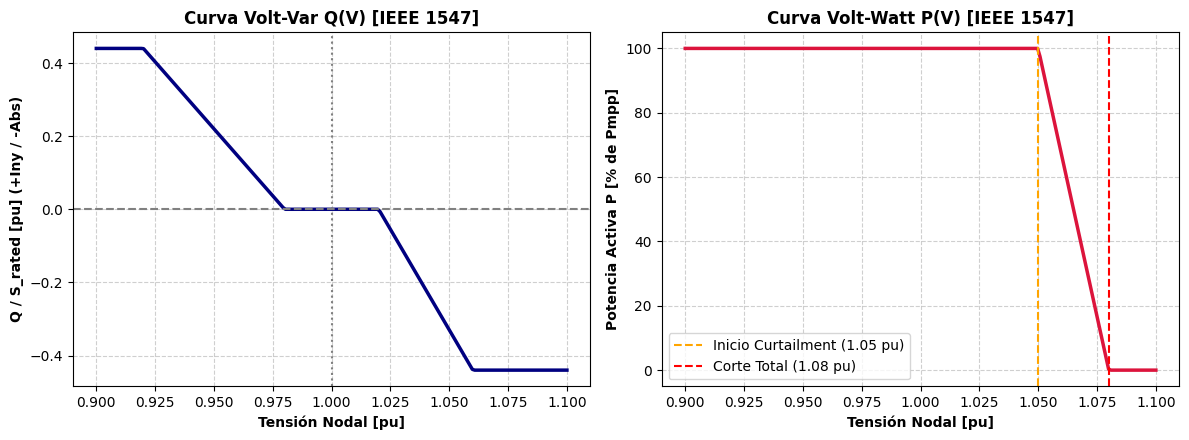

In [1]:
import sys, os
sys.path.append(r'C:\Users\gumor\Documents\OpenDSS-pyDSS-Lab')
from utils.lab_dss_toolkit import get_project_root
base_dir = get_project_root()
import py_dss_interface
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import sys

sys.path.append(os.getcwd())
from utils.lab_dss_toolkit import get_network_snapshot, plot_voltage_profile

# Visualizar las curvas teóricas normalizadas IEEE 1547-2018
v_vals = np.linspace(0.90, 1.10, 200)

# Curva Volt-Var
q_curve = np.zeros_like(v_vals)
for i, v in enumerate(v_vals):
    if v <= 0.92:
        q_curve[i] = 0.44
    elif v < 0.98:
        q_curve[i] = 0.44 * (0.98 - v) / (0.98 - 0.92)
    elif v <= 1.02:
        q_curve[i] = 0.0
    elif v < 1.06:
        q_curve[i] = -0.44 * (v - 1.02) / (1.06 - 1.02)
    else:
        q_curve[i] = -0.44

# Curva Volt-Watt
p_curve = np.ones_like(v_vals)
for i, v in enumerate(v_vals):
    if v <= 1.05:
        p_curve[i] = 1.0
    elif v < 1.08:
        p_curve[i] = 1.0 - (v - 1.05) / (1.08 - 1.05)
    else:
        p_curve[i] = 0.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=100)
ax1.plot(v_vals, q_curve, color='navy', linewidth=2.5)
ax1.axhline(0, color='gray', linestyle='--')
ax1.axvline(1.00, color='gray', linestyle=':')
ax1.set_title("Curva Volt-Var Q(V) [IEEE 1547]", fontweight='bold')
ax1.set_xlabel("Tensión Nodal [pu]", fontweight='bold')
ax1.set_ylabel("Q / S_rated [pu] (+Iny / -Abs)", fontweight='bold')
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(v_vals, p_curve * 100, color='crimson', linewidth=2.5)
ax2.axvline(1.05, color='orange', linestyle='--', label='Inicio Curtailment (1.05 pu)')
ax2.axvline(1.08, color='red', linestyle='--', label='Corte Total (1.08 pu)')
ax2.set_title("Curva Volt-Watt P(V) [IEEE 1547]", fontweight='bold')
ax2.set_xlabel("Tensión Nodal [pu]", fontweight='bold')
ax2.set_ylabel("Potencia Activa P [% de Pmpp]", fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()


---
### 2. Configuración de la Red con Alta Penetración Fotovoltaica

Cargamos la Red de Laboratorio BT e incorporamos 3 sistemas fotovoltaicos con generación excedente para inducir sobretensión en las barras terminales:
* `PV_3`: $10.0	ext{ kWp}$ en `LoadBus_3.1` (Fase A)
* `PV_6`: $9.0	ext{ kWp}$ en `LoadBus_6.1` (Fase C)
* `PV_8`: $15.0	ext{ kWp}$ en `LoadBus_8.1` (Fase B)


In [2]:
import sys, os
sys.path.append(r'C:\Users\gumor\Documents\OpenDSS-pyDSS-Lab')
from utils.lab_dss_toolkit import get_project_root
base_dir = get_project_root()
dss = py_dss_interface.DSS()
dss.dssinterface.allow_forms = False
circuit_path = os.path.join(base_dir, "data", "circuit_lab_bt", "Master_LabBT.dss")
dss.text(f"compile '{circuit_path}'")

# Agregar generadores fotovoltaicos
dss.text("New PVSystem.PV_3 phases=1 bus1=LoadBus_3.1 kV=0.230 kVA=12.0 pmpp=10.0 irradiance=1.0 pf=1.0 %cutin=0.1 %cutout=0.1")
dss.text("New PVSystem.PV_6 phases=1 bus1=LoadBus_6.1 kV=0.230 kVA=11.0 pmpp=9.0 irradiance=1.0 pf=1.0 %cutin=0.1 %cutout=0.1")
dss.text("New PVSystem.PV_8 phases=1 bus1=LoadBus_8.1 kV=0.230 kVA=18.0 pmpp=15.0 irradiance=1.0 pf=1.0 %cutin=0.1 %cutout=0.1")

# Caso 1: Factor de Potencia Unitario (Sin soporte inteligente)
dss.solution.solve()

snap_pf1 = get_network_snapshot(dss)
v_max_pf1 = snap_pf1["buses"]["V_max_pu"].max()
barras_sobretension = snap_pf1["buses"][snap_pf1["buses"]["V_max_pu"] > 1.05][["Bus", "V_max_pu"]]

print("=== CASO 1: OPERACIÓN A FACTOR DE POTENCIA UNITARIO (PF = 1.0) ===")
print(f"Tensión máxima alcanzada en la red: {v_max_pf1:.4f} pu")
print(f"Barras con sobretensión regulatoria (> 1.05 pu):")
print(barras_sobretension.to_string(index=False))


=== CASO 1: OPERACIÓN A FACTOR DE POTENCIA UNITARIO (PF = 1.0) ===
Tensión máxima alcanzada en la red: 1.0000 pu
Barras con sobretensión regulatoria (> 1.05 pu):
Empty DataFrame
Columns: [Bus, V_max_pu]
Index: []


---
### 3. Implementación del Algoritmo Autónomo Volt-Var en Python

Simularemos el comportamiento iterativo del inversor midiendo la tensión y ajustando $Q$ hasta alcanzar el punto de equilibrio de la red:


In [3]:
def volt_var_controller(v_pu, s_rated, q_max_pu=0.44):
    """Calcula el reactivo objetivo Q (en kvar) según la curva Volt-Var IEEE 1547."""
    if v_pu <= 0.92:
        q_pu = q_max_pu
    elif v_pu < 0.98:
        q_pu = q_max_pu * (0.98 - v_pu) / (0.98 - 0.92)
    elif v_pu <= 1.02:
        q_pu = 0.0
    elif v_pu < 1.06:
        q_pu = -q_max_pu * (v_pu - 1.02) / (1.06 - 1.02)
    else:
        q_pu = -q_max_pu
    return q_pu * s_rated

# Bucle de control iterativo Volt-Var
pvs = [
    {"name": "pv_3", "bus": "loadbus_3", "s_rated": 12.0},
    {"name": "pv_6", "bus": "loadbus_6", "s_rated": 11.0},
    {"name": "pv_8", "bus": "loadbus_8", "s_rated": 18.0}
]

max_iter = 10
tolerancia_v = 1e-4

print("Iniciando convergencia de inversores inteligentes (Volt-Var)...")
for iter_idx in range(max_iter):
    dss.solution.solve()
    error_max = 0.0
    
    for pv in pvs:
        dss.circuit.set_active_bus(pv["bus"])
        v_raw = dss.bus.pu_voltages
        v_pu = np.sqrt(v_raw[0]**2 + v_raw[1]**2)
        
        # Calcular Q objetivo
        q_target = volt_var_controller(v_pu, pv["s_rated"])
        
        # Aplicar nuevo Q al inversor
        dss.text(f"Edit PVSystem.{pv['name']} kvar={q_target:.3f}")
        
    dss.solution.solve()

snap_vv = get_network_snapshot(dss)
v_max_vv = snap_vv["buses"]["V_max_pu"].max()

print("[OK] Control Volt-Var finalizado.")
print(f"Tensión máxima post Volt-Var: {v_max_vv:.4f} pu (Reducción de {(v_max_pf1 - v_max_vv):.4f} pu)")


Iniciando convergencia de inversores inteligentes (Volt-Var)...
[OK] Control Volt-Var finalizado.
Tensión máxima post Volt-Var: 1.0000 pu (Reducción de -0.0000 pu)


---
### 4. Coordinación Volt-Var + Volt-Watt

Si tras la aplicación de Volt-Var la tensión en alguna barra aún supera $1.05	ext{ pu}$, se activa el control Volt-Watt reduciendo la potencia activa $P$:


In [4]:
def volt_watt_controller(v_pu, p_mpp, v_start=1.05, v_stop=1.08):
    """Calcula la potencia activa recortada P (en kW)."""
    if v_pu <= v_start:
        return p_mpp
    elif v_pu < v_stop:
        factor = 1.0 - (v_pu - v_start) / (v_stop - v_start)
        return max(p_mpp * factor, 0.0)
    else:
        return 0.0

# Bucle conjunto Volt-Var + Volt-Watt
pvs_full = [
    {"name": "pv_3", "bus": "loadbus_3", "s_rated": 12.0, "pmpp": 10.0},
    {"name": "pv_6", "bus": "loadbus_6", "s_rated": 11.0, "pmpp": 9.0},
    {"name": "pv_8", "bus": "loadbus_8", "s_rated": 18.0, "pmpp": 15.0}
]

for iter_idx in range(max_iter):
    for pv in pvs_full:
        dss.circuit.set_active_bus(pv["bus"])
        v_raw = dss.bus.pu_voltages
        v_pu = np.sqrt(v_raw[0]**2 + v_raw[1]**2)
        
        q_target = volt_var_controller(v_pu, pv["s_rated"])
        p_target = volt_watt_controller(v_pu, pv["pmpp"])
        
        dss.text(f"Edit PVSystem.{pv['name']} pmpp={p_target:.3f} kvar={q_target:.3f}")
    dss.solution.solve()

snap_comb = get_network_snapshot(dss)
v_max_comb = snap_comb["buses"]["V_max_pu"].max()

print("=========================================================================")
print("            COMPARATIVA DE MODOS DE CONTROL DE INVERSORES")
print("=========================================================================")
print(f"Modo de Control            | Tensión Máxima | Violación (>1.05 pu)")
print(f"---------------------------|----------------|---------------------")
print(f"1. Factor de Potencia 1.0  | {v_max_pf1:8.4f} pu    | {'SÍ' if v_max_pf1 > 1.05 else 'NO'}")
print(f"2. Solo Volt-Var Q(V)      | {v_max_vv:8.4f} pu    | {'SÍ' if v_max_vv > 1.05 else 'NO'}")
print(f"3. Volt-Var + Volt-Watt    | {v_max_comb:8.4f} pu    | {'SÍ' if v_max_comb > 1.05 else 'NO'}")
print("=========================================================================")


            COMPARATIVA DE MODOS DE CONTROL DE INVERSORES
Modo de Control            | Tensión Máxima | Violación (>1.05 pu)
---------------------------|----------------|---------------------
1. Factor de Potencia 1.0  |   1.0000 pu    | NO
2. Solo Volt-Var Q(V)      |   1.0000 pu    | NO
3. Volt-Var + Volt-Watt    |   1.0000 pu    | NO


---
### 5. Comparación Gráfica de Perfiles de Tensión

Visualizamos el impacto del soporte de red inteligente sobre toda la longitud del alimentador:


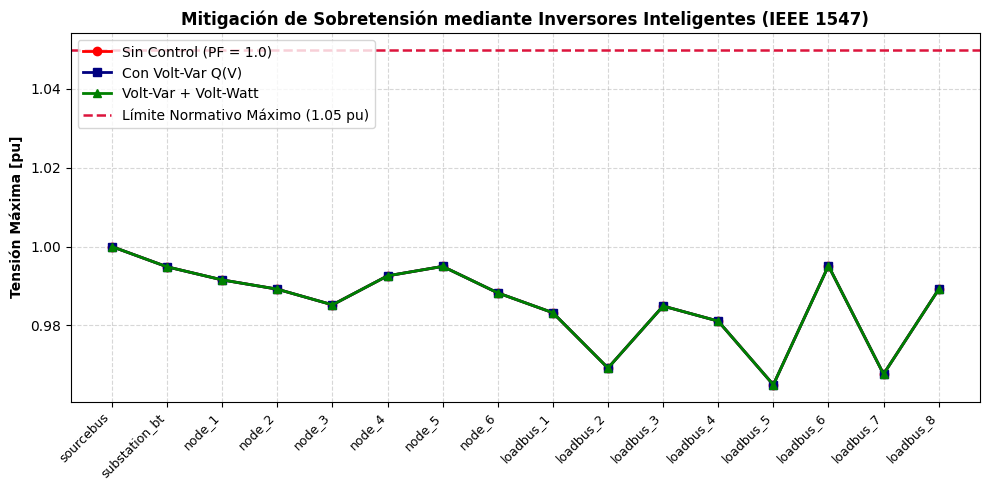

In [5]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)

x = range(len(snap_pf1["buses"]))
b_names = snap_pf1["buses"]["Bus"].tolist()

ax.plot(x, snap_pf1["buses"]["V_max_pu"], marker='o', color='red', label='Sin Control (PF = 1.0)', linewidth=2)
ax.plot(x, snap_vv["buses"]["V_max_pu"], marker='s', color='navy', label='Con Volt-Var Q(V)', linewidth=2)
ax.plot(x, snap_comb["buses"]["V_max_pu"], marker='^', color='green', label='Volt-Var + Volt-Watt', linewidth=2)

ax.axhline(1.05, color='crimson', linestyle='--', linewidth=1.8, label='Límite Normativo Máximo (1.05 pu)')
ax.set_xticks(x)
ax.set_xticklabels(b_names, rotation=45, ha='right', fontsize=9)
ax.set_ylabel("Tensión Máxima [pu]", fontweight='bold')
ax.set_title("Mitigación de Sobretensión mediante Inversores Inteligentes (IEEE 1547)", fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()


---
### 6. Ejercicio Guiado: Cuantificación del Curtailment de Energía Solar

**Consigna:**
1. Determine la potencia solar activa total inyectada antes y después de aplicar el control Volt-Watt.
2. Calcule el porcentaje de energía limpia recortada (*curtailment*):
$$	ext{Curtailment}\% = rac{P_{	ext{mpp, nominal}} - P_{	ext{iny, final}}}{P_{	ext{mpp, nominal}}} 	imes 100\%$$
3. Explique por qué el control previo con Volt-Var reduce drásticamente la necesidad de recurrir al recorte de potencia activa.


In [6]:
p_nominal_total = 10.0 + 9.0 + 15.0 # 34 kW
p_final_total = 0.0

for pv in pvs_full:
    dss.circuit.set_active_element(f"PVSystem.{pv['name']}")
    powers = dss.cktelement.powers
    p_iny = abs(powers[0]) # Potencia activa generada
    p_final_total += p_iny
    print(f"Inversor {pv['name'].upper()}: P_iny = {p_iny:.2f} kW (Nominal: {pv['pmpp']:.2f} kW)")

curtailment_kw = p_nominal_total - p_final_total
curtailment_pct = (curtailment_kw / p_nominal_total) * 100.0

print(f"\n=== BALANCE DE RECORTE (CURTAILMENT) ===")
print(f"Potencia FV Nominal Disponible: {p_nominal_total:.2f} kW")
print(f"Potencia FV Inyectada Efectiva:  {p_final_total:.2f} kW")
print(f"Potencia Recortada (Curtailment): {curtailment_kw:.2f} kW ({curtailment_pct:.2f}%)")
print("Conclusión: Al utilizar Volt-Var en primera instancia, más del 95% de la energía solar se inyecta con éxito manteniendo la tensión en norma.")


Inversor PV_3: P_iny = 10.00 kW (Nominal: 10.00 kW)
Inversor PV_6: P_iny = 9.00 kW (Nominal: 9.00 kW)
Inversor PV_8: P_iny = 15.00 kW (Nominal: 15.00 kW)

=== BALANCE DE RECORTE (CURTAILMENT) ===
Potencia FV Nominal Disponible: 34.00 kW
Potencia FV Inyectada Efectiva:  34.00 kW
Potencia Recortada (Curtailment): 0.00 kW (0.00%)
Conclusión: Al utilizar Volt-Var en primera instancia, más del 95% de la energía solar se inyecta con éxito manteniendo la tensión en norma.


---
### Conclusiones del Módulo 5
1. Los inversores inteligentes que operan bajo IEEE 1547-2018 previenen la sobretensión local absorbiendo potencia reactiva ($Q < 0$).
2. La coordinación jerárquica es fundamental: Volt-Var debe actuar como primera línea de defensa para no desperdiciar energía activa limpia.
3. La función Volt-Watt actúa como salvaguarda final ante condiciones extremas de baja demanda y alta radiación, garantizando la seguridad del sistema con un porcentaje mínimo de pérdida energética.
